# Nano-CT Image Processing of a Li–S Cathode Film using Python and Scikit-Image
Thi-Thanh-Tuyen Truong | NC State University, Chemical and Biomolecular Engineering

## Introduction
X-ray microscopy ("nano-CT") images a sample from many angles and reconstructs it as a stack of cross-sections. Stacking the cross-sections gives a 3D digital copy of the sample, which we can measure without cutting it.

This tutorial walks through the full analysis of a freestanding **FS-S/CNT-PVDF-SDC** sulfur cathode film (a CNT/PVDF soft-dendritic-colloid network loaded with sulfur, about 200 µm thick). It starts from the reconstructed TIFF slices and ends with the numbers reported in the manuscript:

- **porosity** and how it changes through the thickness,
- **pore connectivity** (can electrolyte reach every pore?),
- **sulfur-rich domains** and **pore sizes**,
- **tortuosity**, both geometric (how long the paths are) and diffusive (how much the structure slows ions).

Each step is a short function you can read, run and change. **Practice** prompts invite you to try a variation.

| Dataset | Value |
| --- | --- |
| Instrument | Zeiss Xradia 3D X-ray microscope, 80 kV / 7 W, LE5 filter, 4× objective, binning 2 |
| Scan | 1601 projections over 360°, 6 s each |
| Voxel size | 1.226 µm (isotropic) |
| Data in this folder | 64 slices (470–533) of the 8-bit export, cropped to the film region (+ one full slice) |

**Quick start:** `pip install -r requirements.txt`, then open `nanoCT_tutorial.ipynb` in Jupyter and run all cells (about 7 minutes on a laptop).

| File / folder | What it is |
| --- | --- |
| `nanoCT_tutorial.ipynb` | this tutorial (README.md is the same notebook with its outputs) |
| `ct_tools.py` | the same functions as a module, for scripts: `from ct_tools import analyse_stack` |
| `data/slices/` | 64 cropped 8-bit slices of the film; `data/full_slice_0500.tif` one full slice |
| `data/faces_manuscript.csv` | face positions used for the manuscript numbers |
| `results/` | outputs written by the notebook |

The data are unpublished. If you make this repository public before the paper appears, remove `data/` first.

### Setup environment and modules
Import the libraries first. NumPy holds the 3D image as an array, SciPy and scikit-image do the image processing, and Matplotlib draws the figures.

In [1]:
%matplotlib inline

import glob, json, os, time            # files, results, timing
import numpy as np                     # 3D arrays
import pandas as pd                    # tables
from PIL import Image                  # read / write TIFF slices
from scipy import ndimage as ndi, sparse   # filters, labelling, sparse matrices
from scipy.sparse.linalg import cg     # conjugate-gradient solver (diffusion)
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'],
                     'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})

PX = 1.226424      # voxel size (µm), from the scan header
D_AIR = 40         # air voxels kept in front of the sharp face after alignment
COLORS = dict(pore='#7B5CC8', matrix='#16A08C', srich='#D98E04', transport='#C8402A', geometric='#1F4E8C')
PHASE_CMAP = ListedColormap(['white', COLORS['pore'], COLORS['matrix'], COLORS['srich']])
os.makedirs('results', exist_ok=True)

### Read CT data into Python
To work in 3D, the 2D slices are stacked into one 3D NumPy array: axis 0 is the slice number (z), axis 1 the row along the film (y), axis 2 the column across the film (x). Each element is the grey value of one voxel.

**Read the list of slice files.** `glob` collects every `.tif` in the folder; `sorted` keeps them in slice order.

In [2]:
infiles = sorted(glob.glob('data/slices/*.tif'))
print(len(infiles), 'slices')
infiles[:3]

64 slices


['data/slices/slice_0470.tif',
 'data/slices/slice_0471.tif',
 'data/slices/slice_0472.tif']

The function `stack` opens each slice and copies it into the 3D array. Read it and check how it works.

In [3]:
def stack(files):
    """Read a list of 2D TIFF slices into one 3D array (z, y, x)."""
    first = np.asarray(Image.open(files[0]))
    vol = np.zeros((len(files),) + first.shape, dtype=first.dtype)
    for i, f in enumerate(files):
        vol[i] = np.asarray(Image.open(f))
    return vol

**Call `stack` on the file list and check the size of the 3D array.**

In [4]:
vol = stack(infiles)
print('shape (z, y, x):', vol.shape, '| type:', vol.dtype, '| grey range:', vol.min(), '-', vol.max())

shape (z, y, x): (64, 516, 416) | type: uint8 | grey range: 9 - 222


**Practice 1:** How large is this volume in micrometres? Multiply each dimension by the voxel size `PX`.

In [5]:
print('volume = %.0f × %.0f × %.0f µm (z × y × x)' % tuple(np.array(vol.shape) * PX))

volume = 78 × 633 × 510 µm (z × y × x)


### View imported image
Before any processing, look at the data. The full reconstructed slice shows where the film sits in the field of view; the orange box is the region kept in `data/slices` (with an 8-voxel margin). The film runs top to bottom: its **sharp (smooth) face** is on the left, its **rough face** on the right. Bright dots are sulfur-rich particles; the darker speckle inside the film is the porous CNT/PVDF network.

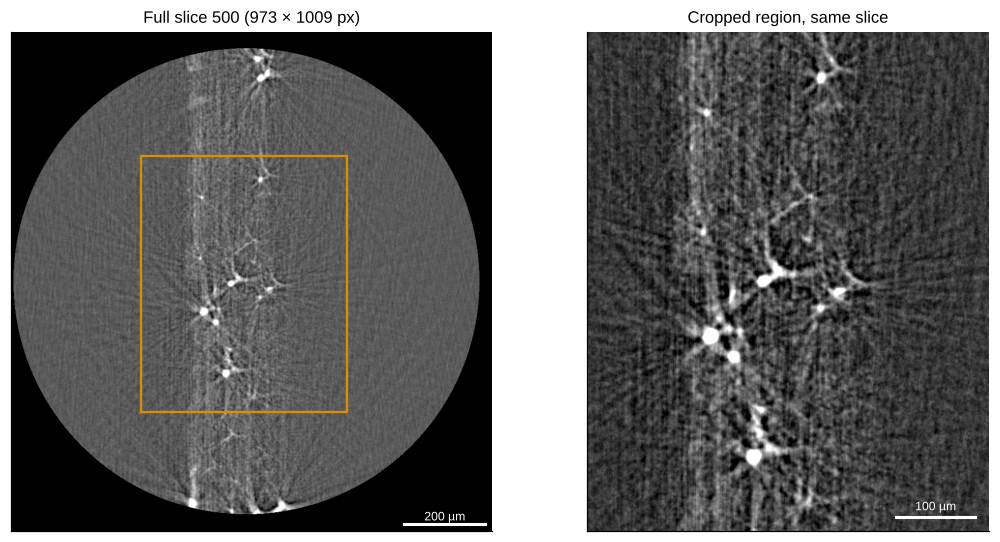

In [6]:
def view(img, ax=None, title='', vmin=40, vmax=95, scalebar_um=100):
    """Show a 2D slice with a linear grey window and a scale bar."""
    ax = ax or plt.gca()
    ax.imshow(img, cmap='gray', vmin=vmin, vmax=vmax)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    if scalebar_um:
        L = scalebar_um / PX; h, w = img.shape
        ax.plot([w - L - 15, w - 15], [h - 15, h - 15], color='white', lw=2)
        ax.text(w - L / 2 - 15, h - 22, f'{scalebar_um} µm', color='white', ha='center', fontsize=8)

full = np.asarray(Image.open('data/full_slice_0500.tif'))
fig, axs = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={'width_ratios': [1, 0.85]})
view(full, axs[0], 'Full slice 500 (973 × 1009 px)', vmin=20, vmax=110, scalebar_um=200)
axs[0].add_patch(plt.Rectangle((262, 251), 416, 516, fill=False, ec=COLORS['srich'], lw=1.5))
view(vol[30], axs[1], 'Cropped region, same slice')
plt.tight_layout()

**Practice 2:** View the first (`vol[0]`) and last (`vol[63]`) slices. Do the faces move between them? (They do: the film is slightly tilted, which we correct below.)

### Pre-processing: denoising
Each voxel carries random noise (about ±2.7 grey levels here). Without filtering, single noisy voxels in the pores would be counted as solid and vice versa. We use a **3D Gaussian filter** with σ = 1 voxel: strong enough to remove pixel noise, weak enough to keep pores of 4–6 voxels (5–8 µm) open.

Non-local-means (NLM) denoising, used in many µCT tutorials, preserves edges better but adds a free parameter (`h`) that changes the result. Below the two are compared on one slice.

In [7]:
def denoise(vol, sigma=1.0):
    """3D Gaussian filter. sigma in voxels; 1 voxel removes pixel noise without merging pores."""
    return ndi.gaussian_filter(vol.astype(np.float32), sigma)

In [8]:
vol_s = denoise(vol, sigma=1.0)
M = 8                                    # crop the margin AFTER filtering, so every kept voxel had real neighbours
raw, vol_s = vol[:, M:-M, M:-M], vol_s[:, M:-M, M:-M]
print('filtered, cropped volume:', vol_s.shape)

filtered, cropped volume: (64, 500, 400)


**Compare raw, Gaussian and NLM on a 100 × 100 µm window, plus a grey-value profile across the film.**

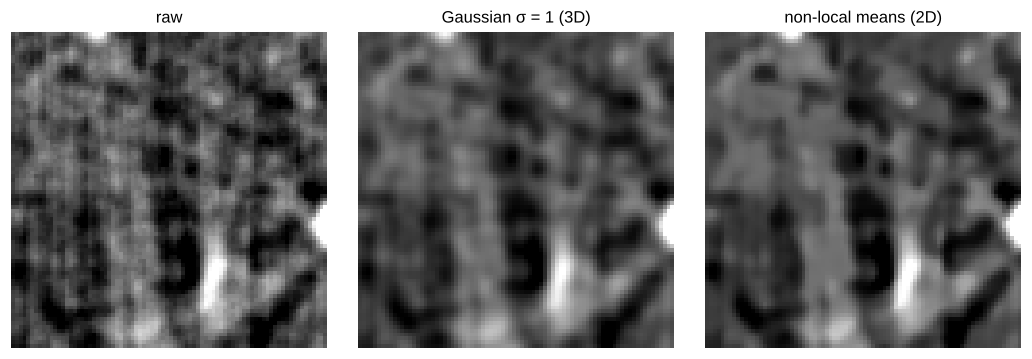

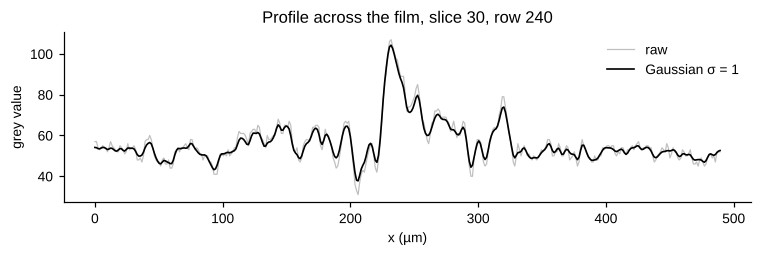

In [9]:
from skimage.restoration import denoise_nl_means

def compare(images, titles, vmin=40, vmax=95):
    fig, axs = plt.subplots(1, len(images), figsize=(3.2 * len(images), 3.2))
    for ax, im, t in zip(axs, images, titles):
        ax.imshow(im, cmap='gray', vmin=vmin, vmax=vmax); ax.set_title(t); ax.axis('off')
    plt.tight_layout()

s2d = raw[30].astype(float)
sigma_raw = raw[:, :, 5:40].std()           # noise of the raw air, used to set the NLM strength
nlm = denoise_nl_means(s2d, h=0.8 * sigma_raw, sigma=sigma_raw, patch_size=5, patch_distance=6, fast_mode=True)
win = (slice(200, 282), slice(90, 172))
compare([s2d[win], vol_s[30][win], nlm[win]], ['raw', 'Gaussian σ = 1 (3D)', 'non-local means (2D)'])

plt.figure(figsize=(7, 2.4)); row = 240
plt.plot(np.arange(raw.shape[2]) * PX, raw[30, row], color='0.75', lw=0.8, label='raw')
plt.plot(np.arange(raw.shape[2]) * PX, vol_s[30, row], color='k', lw=1.1, label='Gaussian σ = 1')
plt.xlabel('x (µm)'); plt.ylabel('grey value'); plt.legend(frameon=False); plt.title('Profile across the film, slice 30, row %d' % row)
plt.tight_layout()

**Practice 3:** Re-run `denoise(vol, sigma=2)` and look at the window again. Which small pores disappear? This is why σ is kept at 1 voxel.

### Find the film faces and correct the tilt
To measure anything *versus depth*, every voxel needs a depth measured from the same face. The film is tilted by a few degrees and its rough face is uneven, so the faces are found locally:

1. Split the rows into **bands of 25 rows** (31 µm).
2. In each band, compute the **fraction of clearly solid voxels** (grey > air + 3 SD) in every column, and smooth it over 9 columns (11 µm).
3. A face is where this fraction first and last exceeds **half of its value inside the film** (half-maximum).
4. A 3 × 3 median filter over (slice, band) removes occasional outlier bands.

The manuscript used a face table made with an earlier version of this step; it is provided as `data/faces_manuscript.csv` so the published numbers can be reproduced exactly. Below, both are compared.

In [10]:
def find_faces(vol_s, band=25, air_cols=(5, 40), k_sd=3, smooth_px=9, frac=0.5):
    """Locate the two film faces in every (slice, band of rows).

    In each band of `band` rows, count the fraction of voxels per column that are clearly solid
    (grey > air mean + k_sd * air SD). Smooth this solid-fraction profile over `smooth_px` columns.
    A face is where it first / last exceeds `frac` x the median solid fraction inside the film
    (half-maximum when frac = 0.5). Outlier bands are removed with a 3 x 3 median filter over
    (slice, band). Returns integer columns x1 (sharp/smooth face) and x2 (rough face), shape (n_slices, n_bands).
    """
    nz, ny, nx = vol_s.shape; nb = ny // band
    air = vol_s[:, :, air_cols[0]:air_cols[1]]; cut = air.mean() + k_sd * air.std()
    x1 = np.zeros((nz, nb)); x2 = np.zeros((nz, nb))
    for z in range(nz):
        for b in range(nb):
            f = (vol_s[z, b * band:(b + 1) * band] > cut).mean(0)
            fs = ndi.uniform_filter1d(f, smooth_px)
            core = np.where(fs > 0.15)[0]                       # provisional film region
            level = np.median(f[core[0]:core[-1] + 1])
            above = np.where(fs > frac * level)[0]
            x1[z, b], x2[z, b] = above[0], above[-1]
    x1 = ndi.median_filter(x1, 3, mode='nearest'); x2 = ndi.median_filter(x2, 3, mode='nearest')
    return x1.astype(int), x2.astype(int)


def load_faces(csv, n_slices, n_bands):
    """Load a face table (columns x_sharp_face, x_rough_face, ordered by slice then band)."""
    import pandas as pd
    f = pd.read_csv(csv)
    return (f.x_sharp_face.values.reshape(n_slices, n_bands).astype(int),
            f.x_rough_face.values.reshape(n_slices, n_bands).astype(int))


def tilt_angle(x1, band=25):
    """Fit a plane x1 = a*z + b*y + c to the sharp-face positions; return the tilt (deg) along z and y."""
    z, b = np.indices(x1.shape); y = b * band + band / 2
    A = np.c_[z.ravel(), y.ravel(), np.ones(z.size)]
    (a, bb, c), *_ = np.linalg.lstsq(A, x1.ravel().astype(float), rcond=None)
    return np.degrees(np.arctan(a)), np.degrees(np.arctan(bb))

In [11]:
x1d, x2d = find_faces(vol_s)                                   # detected here
x1m, x2m = load_faces('data/faces_manuscript.csv', 64, 20)     # used in the manuscript
print('tilt of the sharp face along z: %.1f° (detected), %.1f° (manuscript table)' % (tilt_angle(x1d)[0], tilt_angle(x1m)[0]))
print('sharp face: detected - manuscript = %.1f ± %.1f µm' % ((x1d - x1m).mean() * PX, (x1d - x1m).std() * PX))
print('rough face: detected - manuscript = %.1f ± %.1f µm' % ((x2d - x2m).mean() * PX, (x2d - x2m).std() * PX))
print('mean thickness: %.0f µm (detected), %.0f µm (manuscript table)' % ((x2d - x1d).mean() * PX, (x2m - x1m).mean() * PX))

tilt of the sharp face along z: -6.6° (detected), -5.9° (manuscript table)
sharp face: detected - manuscript = -3.5 ± 3.5 µm
rough face: detected - manuscript = 8.9 ± 11.5 µm
mean thickness: 213 µm (detected), 200 µm (manuscript table)


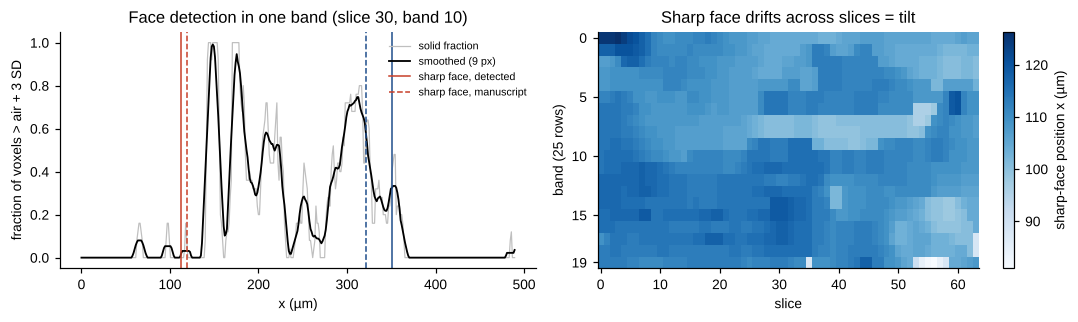

In [12]:
air = vol_s[:, :, 5:40]; cut = air.mean() + 3 * air.std()
z, b = 30, 10
f = (vol_s[z, 25 * b:25 * b + 25] > cut).mean(0); fs = ndi.uniform_filter1d(f, 9); x = np.arange(len(f)) * PX

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].plot(x, f, color='0.75', lw=0.8, label='solid fraction'); axs[0].plot(x, fs, color='k', lw=1.2, label='smoothed (9 px)')
for xx, ls, lab in ((x1d[z, b], '-', 'detected'), (x1m[z, b], '--', 'manuscript')):
    axs[0].axvline(xx * PX, color=COLORS['transport'], ls=ls, lw=1, label=f'sharp face, {lab}')
for xx, ls in ((x2d[z, b], '-'), (x2m[z, b], '--')):
    axs[0].axvline(xx * PX, color=COLORS['geometric'], ls=ls, lw=1)
axs[0].set_xlabel('x (µm)'); axs[0].set_ylabel('fraction of voxels > air + 3 SD'); axs[0].legend(frameon=False, fontsize=7)
axs[0].set_title('Face detection in one band (slice %d, band %d)' % (z, b))
im = axs[1].imshow((x1d * PX).T, aspect='auto', cmap='Blues'); plt.colorbar(im, ax=axs[1], label='sharp-face position x (µm)')
axs[1].set_xlabel('slice'); axs[1].set_ylabel('band (25 rows)'); axs[1].set_yticks([0, 5, 10, 15, 19]); axs[1].set_title('Sharp face drifts across slices = tilt')
plt.tight_layout()

The sharp face agrees within a few micrometres; the rough face is less well defined (it is rough), so the two methods differ more there. Later, the section *How do I know it is accurate?* shows how much this choice changes the results.

**Align the film.** `align` shifts every band so its sharp face sits at depth index `D_AIR` = 40, keeping 40 voxels of air in front of the film. `rough` stores the local depth of the rough face. `film_mask` cuts a 163-voxel (200 µm) slab and marks which voxels are inside the film.

In [13]:
def align(vol_s, x1, x2, band=25, depth=280):
    """Shift every band so its sharp face sits at depth index D_AIR.

    Returns the aligned volume (z, y, depth) and `rough` (z, y): the local depth (voxels) of the
    rough face measured from the sharp face. Voxels deeper than `rough` are outside the film.
    """
    nz, nb = x1.shape
    A = np.zeros((nz, nb * band, depth), np.float32); rough = np.zeros((nz, nb * band), int)
    for z in range(nz):
        for b in range(nb):
            s = x1[z, b] - D_AIR
            A[z, b * band:(b + 1) * band] = vol_s[z, b * band:(b + 1) * band, s:s + depth]
            rough[z, b * band:(b + 1) * band] = x2[z, b] - x1[z, b]
    return A, rough


def film_mask(A, rough, h=163):
    """Film slab (from the sharp face, h voxels deep; 163 voxels = 200 µm here) and the mask of voxels inside the film."""
    film = A[:, :, D_AIR:D_AIR + h]
    inside = np.arange(h)[None, None, :] < rough[:, :, None]
    return film, inside

aligned volume: (64, 500, 280) | film slab: (64, 500, 163) | median local thickness 201 µm


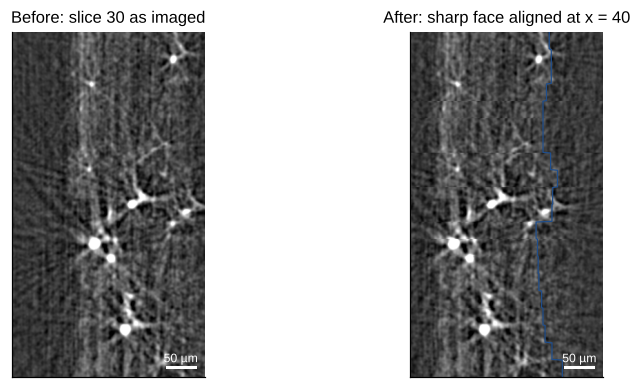

In [14]:
A, rough = align(vol_s, x1m, x2m)          # manuscript faces, to reproduce the published numbers
film, inside = film_mask(A, rough)
print('aligned volume:', A.shape, '| film slab:', film.shape, '| median local thickness %.0f µm' % (np.median(rough) * PX))

fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
view(vol_s[30, :, :280], axs[0], 'Before: slice 30 as imaged', scalebar_um=50)
view(A[30], axs[1], 'After: sharp face aligned at x = 40', scalebar_um=50)
axs[1].plot(D_AIR + rough[30], np.arange(A.shape[1]), color=COLORS['geometric'], lw=0.8)
plt.tight_layout()

**Practice 4:** Run `find_faces(vol_s, frac=0.4)` and `frac=0.6`. How does the mean thickness change? The half-maximum (`frac=0.5`) is the usual convention.

### Segmentation
Segmentation assigns every voxel to a phase: **pore**, **CNT/PVDF matrix** or **S-rich**. First look at the histogram.

In [15]:
def air_stats(A, depth_range=(5, 30)):
    """Mean and SD of the air in front of the sharp face (aligned depth indices 5-30)."""
    air = A[:, :, depth_range[0]:depth_range[1]]
    return float(air.mean()), float(air.std())


def thresholds(air_mean, air_sd, ks=(2, 3, 4)):
    """Pore cut-offs air mean + k*SD."""
    return {f'{k}sd': air_mean + k * air_sd for k in ks}


def segment(film, inside, t_pore, t_s=75):
    """Three phases: 0 = outside film, 1 = pore, 2 = matrix, 3 = S-rich."""
    lab = np.zeros(film.shape, np.uint8)
    lab[inside & (film <= t_pore)] = 1
    lab[inside & (film > t_pore) & (film < t_s)] = 2
    lab[inside & (film >= t_s)] = 3
    return lab

air right in front of the film: 51.88 ± 2.83
air used in the manuscript (far from the film): 52.02 ± 1.84


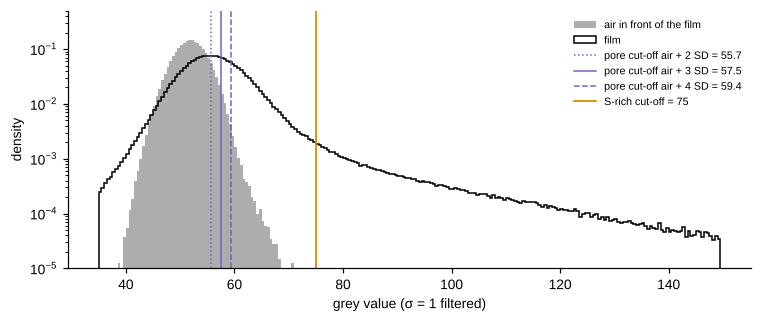

In [16]:
def plothist(film, inside, A, bins=np.arange(35, 150, 0.5)):
    plt.figure(figsize=(7, 3))
    plt.hist(A[:, :, 5:30].ravel(), bins=bins, density=True, color='0.6', alpha=0.8, label='air in front of the film')
    plt.hist(film[inside].ravel(), bins=bins, density=True, histtype='step', color='k', lw=1, label='film')
    plt.yscale('log'); plt.ylim(1e-5, 0.5); plt.xlabel('grey value (σ = 1 filtered)'); plt.ylabel('density')

plothist(film, inside, A)
AIR_MS = (52.02, 1.84)                                        # far-air statistics used in the manuscript
thr = thresholds(*AIR_MS)
for (k, t), ls in zip(thr.items(), (':', '-', '--')):
    plt.axvline(t, color=COLORS['pore'], ls=ls, lw=1, label=f'pore cut-off air + {k[0]} SD = {t:.1f}')
plt.axvline(75, color=COLORS['srich'], lw=1.2, label='S-rich cut-off = 75')
plt.legend(frameon=False, fontsize=7); plt.tight_layout()

print('air right in front of the film: %.2f ± %.2f' % air_stats(A))
print('air used in the manuscript (far from the film): %.2f ± %.2f' % AIR_MS)

The film histogram has no clean valley between pore and matrix: at 1.23 µm, many voxels are a mix of both. A single "best" threshold therefore does not exist. Instead the pore cut-off is tied to the **noise of the air** (air mean + 2, 3 or 4 SD), and every result is reported as a range over these three cut-offs. Voxels ≥ 75 (about air + 12 SD) are S-rich; everything between is matrix.

Where the air noise is measured matters. The cell below shows that the noise of the air **increases as you approach the film**, while its mean stays at about 52. This is typical of CT: rays that pass through the sample carry more noise and streak artifacts, and ring removal was off in this reconstruction. The manuscript used air far from the film (SD 1.84). The noise inside the film is probably closer to the near-film value, so the manuscript cut-offs sit at the low (conservative) end. The effect is tested in *How do I know it is accurate?*

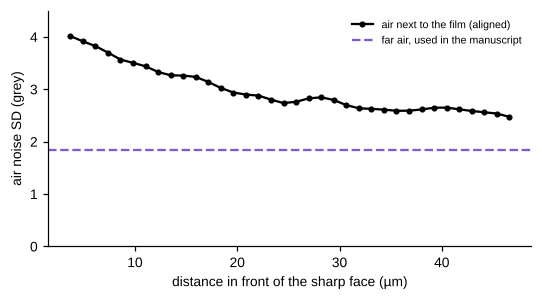

In [17]:
dist = (D_AIR - np.arange(2, 38)) * PX
sd_d = [A[:, :, k].std() for k in range(2, 38)]
plt.figure(figsize=(5, 2.8)); plt.plot(dist, sd_d, 'o-', ms=3, color='k', label='air next to the film (aligned)')
plt.axhline(AIR_MS[1], color=COLORS['pore'], ls='--', label='far air, used in the manuscript')
plt.xlabel('distance in front of the sharp face (µm)'); plt.ylabel('air noise SD (grey)'); plt.legend(frameon=False, fontsize=7); plt.ylim(0, 4.5)
plt.tight_layout()

**Visualise the segmentation next to the raw data.**

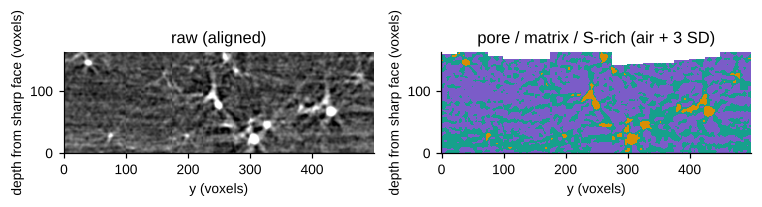

In [18]:
lab = segment(film, inside, thr['3sd'])
fig, axs = plt.subplots(1, 2, figsize=(7, 4.5))
axs[0].imshow(film[30].T, cmap='gray', vmin=40, vmax=95, origin='lower', aspect='equal'); axs[0].set_title('raw (aligned)')
axs[1].imshow(lab[30].T, cmap=PHASE_CMAP, vmin=0, vmax=3, origin='lower', aspect='equal', interpolation='nearest')
axs[1].set_title('pore / matrix / S-rich (air + 3 SD)')
for ax in axs: ax.set_xlabel('y (voxels)'); ax.set_ylabel('depth from sharp face (voxels)')
plt.tight_layout()

#### Marker-based segmentation (cross-check)
Marker-based methods label only the voxels that are certainly one phase (the *markers*) and let an algorithm decide the uncertain ones in between. Here the random walker does this on one slice, as an independent check on the threshold range:
- pore marker: grey ≤ air + 1 SD; matrix marker: air + 6 SD ≤ grey < 75; S-rich marker: grey ≥ 75.

porosity in this slice: random walker 66.8% | thresholds air + 2/3/4 SD: 44.5 / 56.5 / 67.4%


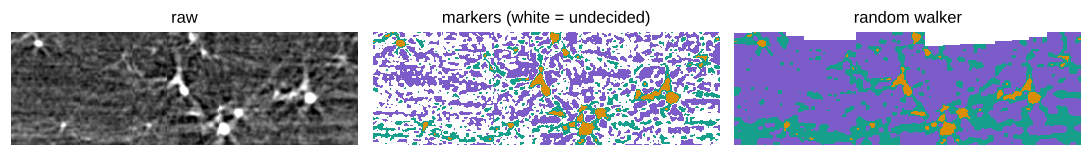

In [19]:
from skimage.segmentation import random_walker

s = film[30]; ins = inside[30]
markers = np.zeros(s.shape, np.uint8)
markers[(s <= AIR_MS[0] + 1 * AIR_MS[1])] = 1
markers[(s >= AIR_MS[0] + 6 * AIR_MS[1]) & (s < 75)] = 2
markers[s >= 75] = 3
rw = random_walker((s - s.mean()) / s.std(), markers, beta=50, mode='cg_j', tol=1e-4)

por_rw = 100 * ((rw == 1) & ins).sum() / ins.sum()
por_thr = [100 * ((s <= t) & ins).sum() / ins.sum() for t in thr.values()]
print('porosity in this slice: random walker %.1f%% | thresholds air + 2/3/4 SD: %.1f / %.1f / %.1f%%' % (por_rw, *por_thr))

fig, axs = plt.subplots(1, 3, figsize=(10, 4))
axs[0].imshow(s.T, cmap='gray', vmin=40, vmax=95, origin='lower'); axs[0].set_title('raw')
axs[1].imshow(markers.T, cmap=PHASE_CMAP, vmin=0, vmax=3, origin='lower', interpolation='nearest'); axs[1].set_title('markers (white = undecided)')
axs[2].imshow(np.where(ins, rw, 0).T, cmap=PHASE_CMAP, vmin=0, vmax=3, origin='lower', interpolation='nearest'); axs[2].set_title('random walker')
for ax in axs: ax.axis('off')
plt.tight_layout()

**Practice 5:** Change the marker limits (e.g. pore ≤ air + 2 SD, matrix ≥ air + 5 SD) and `beta`. Does the random-walker porosity stay inside the threshold range?

### Porosity and depth profiles
Porosity is the fraction of film voxels that are pore. Computing it plane by plane gives the **depth profile**, which reveals any gradient through the thickness. A **dense layer** is defined objectively as the depths where porosity (air + 3 SD) falls below the bulk mean − 2 SD (bulk: 50–170 µm).

In [20]:
def depth_profiles(film, inside, thr, t_s=75, air_mean=None):
    """Porosity (per threshold), S-rich fraction and film fraction versus depth."""
    n_in = inside.sum((0, 1)).astype(float); ok = n_in > 0
    out = {'depth_um': np.arange(film.shape[2]) * PX, 'film_fraction': inside.mean((0, 1))}
    for k, t in thr.items():
        v = ((film <= t) & inside).sum((0, 1)) / np.where(ok, n_in, 1)
        out[f'porosity_{k}'] = np.where(ok, 100 * v, np.nan)
    out['S_rich_pct'] = np.where(ok, 100 * ((film >= t_s) & inside).sum((0, 1)) / np.where(ok, n_in, 1), np.nan)
    if air_mean is not None:
        out['mean_excess_grey'] = np.where(ok, (np.where(inside, film, 0).sum((0, 1)) / np.where(ok, n_in, 1)) - air_mean, np.nan)
    return out


def dense_layer(depth_um, porosity, bulk=(50, 170), n_sd=2, search_to=80):
    """Depths (µm) where porosity (3-pt mean) falls below bulk mean - n_sd*SD, within the first `search_to` µm."""
    sm = np.convolve(np.nan_to_num(porosity, nan=np.nanmean(porosity)), np.ones(3) / 3, mode='same')
    b = (depth_um > bulk[0]) & (depth_um < bulk[1])
    cut = np.nanmean(porosity[b]) - n_sd * np.nanstd(porosity[b])
    low = depth_um[(sm < cut) & (depth_um < search_to)]
    return (float(low.min()), float(low.max())) if len(low) else None, float(cut)

porosity air + 2 SD: 47.0%
porosity air + 3 SD: 60.6%
porosity air + 4 SD: 72.2%
dense layer: 0-43 µm from the sharp face (porosity below 58.2%)


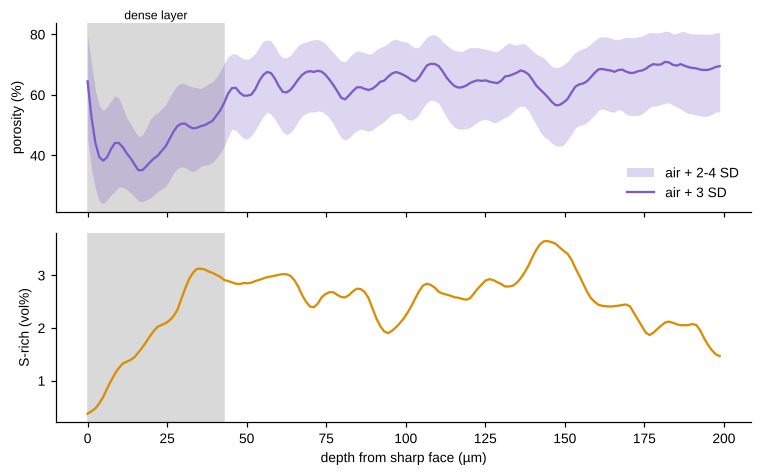

In [21]:
prof = depth_profiles(film, inside, thr, air_mean=AIR_MS[0])
dl, cut = dense_layer(prof['depth_um'], prof['porosity_3sd'])
for k in thr: print('porosity air + %s SD: %.1f%%' % (k[0], 100 * ((film <= thr[k]) & inside).sum() / inside.sum()))
print('dense layer: %.0f-%.0f µm from the sharp face (porosity below %.1f%%)' % (dl[0], dl[1], cut))

d = prof['depth_um']
fig, axs = plt.subplots(2, 1, figsize=(7, 4.4), sharex=True)
axs[0].fill_between(d, prof['porosity_2sd'], prof['porosity_4sd'], color=COLORS['pore'], alpha=0.25, lw=0, label='air + 2-4 SD')
axs[0].plot(d, prof['porosity_3sd'], color=COLORS['pore'], label='air + 3 SD'); axs[0].set_ylabel('porosity (%)'); axs[0].legend(frameon=False)
axs[1].plot(d, pd.Series(prof['S_rich_pct']).rolling(5, center=True, min_periods=1).mean(), color=COLORS['srich']); axs[1].set_ylabel('S-rich (vol%)')
axs[1].set_xlabel('depth from sharp face (µm)')
for ax in axs: ax.axvspan(*dl, color='0.85', zorder=-1)
axs[0].text(np.mean(dl), 85, 'dense layer', ha='center', fontsize=8)
plt.tight_layout()

### Pore connectivity
A pore only helps if electrolyte can reach it. Pores are labelled as connected groups (6-connectivity: voxels touching by a face). Each film face is modelled as an electrolyte reservoir by adding one fully open layer outside it. A pore group touching **both** reservoirs is *through-connected*; one touching only one face is a *dead end*; one touching neither is *isolated*.

In [22]:
def connectivity(pore, inside):
    """Classify pore voxels as through (touch both faces), dead-end (one face) or isolated (none).

    `pore` should include voxels beyond the rough face (they are open electrolyte). Faces are
    modelled as reservoirs by padding one fully open layer on each side; 6-connectivity.
    """
    P = np.pad(pore, ((0, 0), (0, 0), (1, 1)), constant_values=True)
    lab, _ = ndi.label(P)
    a = set(np.unique(lab[:, :, 0])) - {0}; b = set(np.unique(lab[:, :, -1])) - {0}
    lab = lab[:, :, 1:-1]; pin = pore & inside
    through = np.isin(lab, list(a & b)) & pin
    isolated = pin & ~np.isin(lab, list(a | b))
    dead = pin & ~through & ~isolated
    return dict(through=through, dead_end=dead, isolated=isolated,
                through_pct=100 * through.sum() / pin.sum(), dead_end_pct=100 * dead.sum() / pin.sum(),
                isolated_pct=100 * isolated.sum() / pin.sum())

through 99.93% | dead-end 0.000% | isolated 0.070% of the pore volume


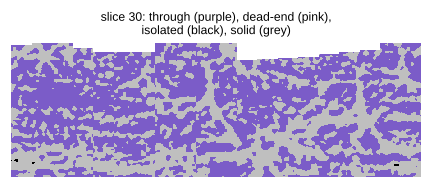

In [23]:
pore3 = (film <= thr['3sd']) | ~inside          # beyond the rough face counts as open electrolyte
con = connectivity(pore3, inside)
print('through %.2f%% | dead-end %.3f%% | isolated %.3f%% of the pore volume' % (con['through_pct'], con['dead_end_pct'], con['isolated_pct']))

show = np.zeros(film.shape[1:], np.uint8); zz = 30
show[inside[zz]] = 1; show[con['through'][zz]] = 2; show[con['dead_end'][zz]] = 3; show[con['isolated'][zz]] = 4
plt.figure(figsize=(4, 4.5))
plt.imshow(show.T, cmap=ListedColormap(['white', '0.75', COLORS['pore'], '#E377C2', 'k']), vmin=0, vmax=4, origin='lower', interpolation='nearest')
plt.title('slice 30: through (purple), dead-end (pink),\nisolated (black), solid (grey)', fontsize=8); plt.axis('off'); plt.tight_layout()

### Sulfur-rich domains
S-rich voxels are grouped into 3D clusters (26-connectivity: touching by a face, edge or corner). Clusters smaller than 4 voxels are ignored as noise. Each cluster's size is expressed as the diameter of a sphere of equal volume.

In [24]:
def s_clusters(film, inside, t_s=75, min_vox=4):
    """26-connected S-rich clusters >= min_vox voxels: equivalent diameter (µm) and centroid depth (µm)."""
    bright = (film >= t_s) & inside
    lab, n = ndi.label(bright, structure=np.ones((3, 3, 3)))
    cnt = np.bincount(lab.ravel())[1:]; keep = np.where(cnt >= min_vox)[0] + 1
    dia = (6 * cnt[keep - 1] * PX ** 3 / np.pi) ** (1 / 3)
    depth = np.array(ndi.center_of_mass(bright, lab, keep))[:, 2] * PX
    return dict(diameter_um=dia, depth_um=depth, vol_pct=100 * bright.sum() / inside.sum())

193 clusters | S-rich 2.47 vol% | median diameter 5.9 µm (IQR 4.0-8.7)


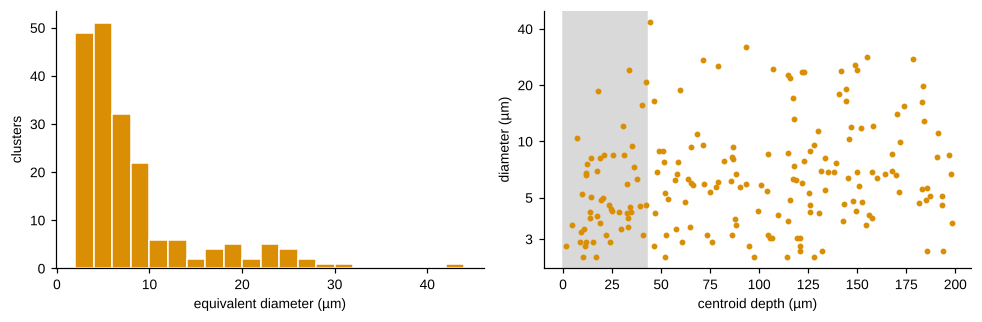

In [25]:
cl = s_clusters(film, inside)
dia, dep = cl['diameter_um'], cl['depth_um']
print('%d clusters | S-rich %.2f vol%% | median diameter %.1f µm (IQR %.1f-%.1f)' % (len(dia), cl['vol_pct'], np.median(dia), *np.percentile(dia, [25, 75])))

fig, axs = plt.subplots(1, 2, figsize=(9, 3))
axs[0].hist(dia, bins=np.arange(2, 46, 2), color=COLORS['srich'], edgecolor='white'); axs[0].set_xlabel('equivalent diameter (µm)'); axs[0].set_ylabel('clusters')
axs[1].scatter(dep, dia, s=8, color=COLORS['srich']); axs[1].set_yscale('log'); axs[1].axvspan(*dl, color='0.85', zorder=-1)
axs[1].set_yticks([3, 5, 10, 20, 40]); axs[1].set_yticklabels(['3', '5', '10', '20', '40']); axs[1].minorticks_off()
axs[1].set_xlabel('centroid depth (µm)'); axs[1].set_ylabel('diameter (µm)')
plt.tight_layout()

### Pore size
The local pore diameter is twice the distance from a pore voxel to the nearest solid (Euclidean distance transform), read along the pore **skeleton**, the one-voxel-wide centre line of the pore network. The transport calculations below use rows 250–500 of the region (78 × 307 × 200 µm³) to keep run times short; pore sizes are taken from the same sub-volume.

In [26]:
def pore_diameters(pore, inside):
    """Local pore diameter = 2 x distance to the nearest solid, sampled on the pore skeleton (µm)."""
    from skimage.morphology import skeletonize
    sk = skeletonize(pore) > 0
    dt = ndi.distance_transform_edt(pore) * PX
    return 2 * dt[sk & inside]

median local pore diameter: 6.9 µm


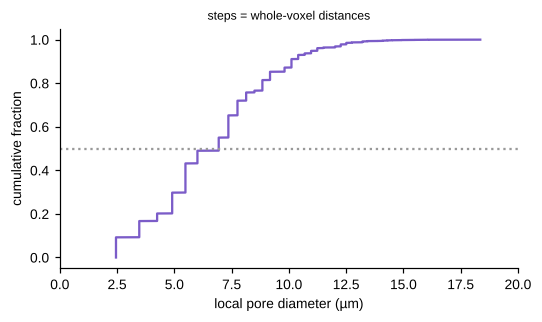

In [27]:
R0, R1 = 250, 500
pd3 = pore_diameters(pore3[:, R0:R1], inside[:, R0:R1])
print('median local pore diameter: %.1f µm' % np.median(pd3))
xs = np.sort(pd3); plt.figure(figsize=(5, 3)); plt.plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=COLORS['pore'])
plt.axhline(0.5, color='0.6', ls=':'); plt.xlim(0, 20); plt.title('steps = whole-voxel distances', fontsize=8); plt.xlabel('local pore diameter (µm)'); plt.ylabel('cumulative fraction'); plt.tight_layout()

### Tortuosity
Two different quantities are both called "tortuosity":

- **Geometric tortuosity** $\tau_{geo} = L/H$: the length $L$ of the shortest path through the pores divided by the film thickness $H$. It only measures how *long* the paths are.
- **Tortuosity factor** $\tau_f = \varepsilon / (D_{eff}/D_0)$: how much the pore structure reduces diffusion compared with free electrolyte, at porosity $\varepsilon$. It also counts narrowings, widenings and dead ends, and is the quantity used in electrochemical models (MacMullin number $N_M = \tau_f/\varepsilon$).

**Geometric tortuosity.** Minimum-cost paths (scikit-image `MCP_Geometric`, 26-neighbour moves) are found from the sharp face to the far face.

In [28]:
def geometric_tortuosity(pore, start_step=5):
    """Shortest pore paths from the sharp face (depth 0) to the far face; tau_geo = median length / thickness.

    Minimum-cost paths with 26-neighbour moves (skimage MCP_Geometric). Every `start_step`-th
    open voxel on the sharp face is used as a start point.
    """
    from skimage.graph import MCP_Geometric
    mcp = MCP_Geometric(np.where(pore, 1.0, np.inf), sampling=(PX, PX, PX))
    starts = np.argwhere(pore[:, :, 0])[::start_step]
    cost, _ = mcp.find_costs([(int(a), int(b), 0) for a, b in starts])
    end = cost[:, :, -1][pore[:, :, -1]]; end = end[np.isfinite(end)]
    H = (pore.shape[2] - 1) * PX
    return float(np.median(end) / H), mcp, cost


def path_tortuosity(mcp, cost, pore, n=400, bin_vox=8, seed=1):
    """Trace n shortest paths back from random end voxels; whole-path and local (per depth bin) tortuosity."""
    H = (pore.shape[2] - 1) * PX
    ends = np.argwhere(pore[:, :, -1] & np.isfinite(cost[:, :, -1]))
    sel = np.random.default_rng(seed).choice(len(ends), min(n, len(ends)), replace=False)
    taus, local, paths = [], [], []
    for k in sel:
        p = np.array(mcp.traceback((int(ends[k, 0]), int(ends[k, 1]), pore.shape[2] - 1)))
        seg = np.linalg.norm(np.diff(p * PX, axis=0), axis=1)
        taus.append(seg.sum() / H); paths.append(p)
        b = np.floor(((p[1:, 2] + p[:-1, 2]) / 2) / bin_vox).astype(int)
        for j in range((pore.shape[2] - 1) // bin_vox):
            local.append(((j + 0.5) * bin_vox * PX, seg[b == j].sum() / (bin_vox * PX)))
    return np.array(taus), np.array(local), paths

tau_geo = 1.072 | 400 traced paths: median 1.071, max 1.109  [1 s]


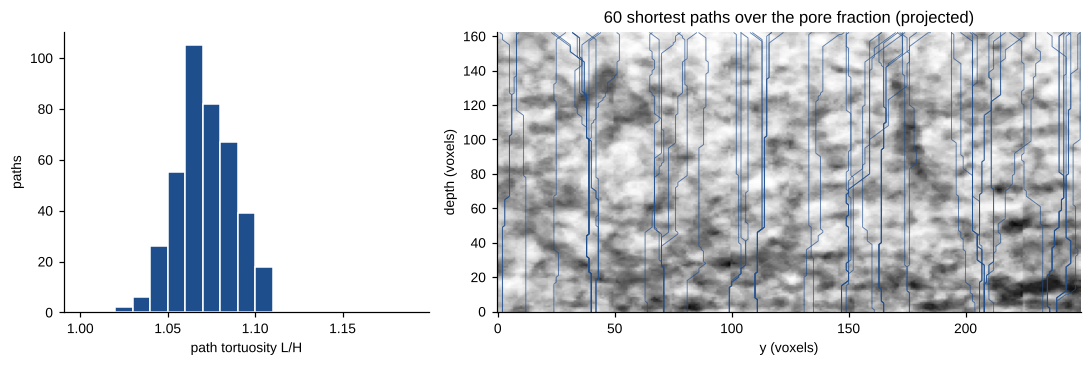

In [29]:
sub = pore3[:, R0:R1]
t0 = time.time()
tau_geo, mcp, cost = geometric_tortuosity(sub)
taus, local_geo, paths = path_tortuosity(mcp, cost, sub, n=400)
print('tau_geo = %.3f | 400 traced paths: median %.3f, max %.3f  [%.0f s]' % (tau_geo, np.median(taus), taus.max(), time.time() - t0))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={'width_ratios': [1, 1.6]})
axs[0].hist(taus, bins=np.arange(1, 1.2, 0.01), color=COLORS['geometric'], edgecolor='white'); axs[0].set_xlabel('path tortuosity L/H'); axs[0].set_ylabel('paths')
axs[1].imshow(sub.mean(0).T, cmap='Greys_r', origin='lower', aspect='auto', vmin=0, vmax=1)
for p in paths[:60]: axs[1].plot(p[:, 1], p[:, 2], color=COLORS['geometric'], lw=0.6, alpha=0.7)
axs[1].set_xlabel('y (voxels)'); axs[1].set_ylabel('depth (voxels)'); axs[1].set_title('60 shortest paths over the pore fraction (projected)')
plt.tight_layout()

**Tortuosity factor.** Steady-state diffusion (Laplace's equation, $\nabla^2 c = 0$) is solved in the through-connected pores with $c = 1$ on the sharp face, $c = 0$ on the far face and no flux through the side walls. Each pore voxel is one unknown; neighbouring pore voxels are linked by a unit conductance. The flux $J$ through the film gives $D_{eff}/D_0 = J\,H/(\Delta c\,A)$. The same method is used by TauFactor (Cooper et al., 2016).

Two checks: the flux leaving must equal the flux entering, and the solver must report convergence (`cg_info = 0`).

In [30]:
def diffusion_tortuosity(pore, rtol=1e-8, maxiter=50000):
    """Steady-state diffusion through the face-to-face connected pores (Laplace equation, D0 = 1).

    c = 1 on the sharp face (depth 0), c = 0 on the far face (half-voxel Dirichlet), no flux on the
    side walls. Solved with Jacobi-preconditioned conjugate gradients.
    Returns D_eff/D0, tau_f = eps / (D_eff/D0), the concentration field, and a flux-balance check.
    """
    conn = connectivity(pore, np.ones_like(pore))['through']
    nid = -np.ones(pore.shape, np.int64); nid[conn] = np.arange(conn.sum()); N = int(conn.sum())
    rows, cols, diag = [], [], np.zeros(N); rhs = np.zeros(N)
    for ax in range(3):
        a_ = [slice(None)] * 3; b_ = [slice(None)] * 3; a_[ax] = slice(0, -1); b_[ax] = slice(1, None)
        m = conn[tuple(a_)] & conn[tuple(b_)]; i = nid[tuple(a_)][m]; j = nid[tuple(b_)][m]
        rows += [i, j]; cols += [j, i]; np.add.at(diag, i, 1.0); np.add.at(diag, j, 1.0)
    g = 2.0                                                 # half-voxel conductance to the boundary
    b0 = nid[:, :, 0][conn[:, :, 0]]; np.add.at(diag, b0, g); np.add.at(rhs, b0, g)
    b1 = nid[:, :, -1][conn[:, :, -1]]; np.add.at(diag, b1, g)
    r_, c_ = np.concatenate(rows), np.concatenate(cols)
    M = sparse.csr_matrix((-np.ones(len(r_)), (r_, c_)), shape=(N, N)) + sparse.diags(diag)
    c, info = cg(M, rhs, M=sparse.diags(1 / diag), rtol=rtol, maxiter=maxiter)
    J_in = (g * (1 - c[b0])).sum(); J_out = (g * c[b1]).sum()
    area = pore.shape[0] * pore.shape[1]
    Deff = J_in * pore.shape[2] / area
    eps = float(pore.mean())
    C = np.full(pore.shape, np.nan, np.float32); C[conn] = c
    return dict(Deff=float(Deff), tau_f=eps / Deff, eps=eps, C=C, J=J_in / area,
                flux_balance=float(abs(J_in - J_out) / J_in), cg_info=int(info))


def local_tau_f(C, pore, J, window=9):
    """Local tortuosity factor tau_f(z) = eps(z) * |d c_mean/dz| / J (slope from a `window`-voxel linear fit)."""
    cbar = np.nanmean(C, axis=(0, 1)); eps = pore.mean((0, 1)); n = len(cbar); h = window // 2
    dc = np.full(n, np.nan); zz = np.arange(n)
    for z in range(h, n - h):
        dc[z] = -np.polyfit(zz[z - h:z + h + 1], cbar[z - h:z + h + 1], 1)[0]
    return cbar, eps * dc / J

D_eff/D0 = 0.287 | tau_f = 2.14 | porosity of domain = 0.614 | MacMullin = 3.5
flux in vs out: relative difference 5.2e-07 | solver status 0  [36 s]


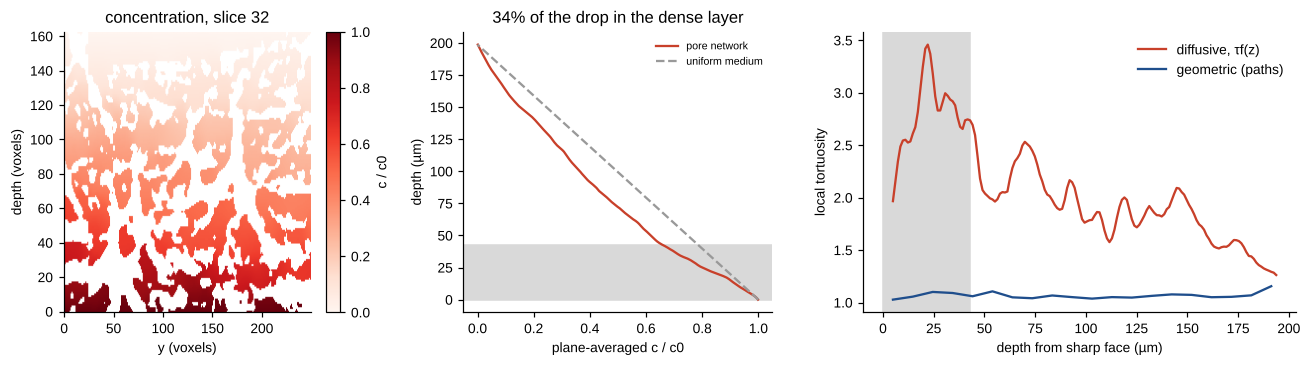

In [31]:
t0 = time.time()
dres = diffusion_tortuosity(sub)
print('D_eff/D0 = %.3f | tau_f = %.2f | porosity of domain = %.3f | MacMullin = %.1f' % (dres['Deff'], dres['tau_f'], dres['eps'], dres['tau_f'] / dres['eps']))
print('flux in vs out: relative difference %.1e | solver status %d  [%.0f s]' % (dres['flux_balance'], dres['cg_info'], time.time() - t0))

cbar, tau_loc = local_tau_f(dres['C'], sub, dres['J'])
depth = np.arange(sub.shape[2]) * PX
cs = np.unique(local_geo[:, 0]); geo_mean = [local_geo[local_geo[:, 0] == c, 1].mean() for c in cs]
drop = 100 * (1 - np.interp(dl[1], depth, cbar))

fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={'width_ratios': [1, 1, 1.4]})
im = axs[0].imshow(dres['C'][32].T, cmap='Reds', origin='lower', vmin=0, vmax=1, aspect='auto'); plt.colorbar(im, ax=axs[0], label='c / c0')
axs[0].set_title('concentration, slice 32'); axs[0].set_xlabel('y (voxels)'); axs[0].set_ylabel('depth (voxels)')
axs[1].plot(cbar, depth, color=COLORS['transport'], label='pore network'); axs[1].plot([1, 0], [0, depth[-1]], '--', color='0.6', label='uniform medium')
axs[1].axhspan(*dl, color='0.85', zorder=-1); axs[1].set_xlabel('plane-averaged c / c0'); axs[1].set_ylabel('depth (µm)'); axs[1].legend(frameon=False, fontsize=7)
axs[1].set_title('%.0f%% of the drop in the dense layer' % drop)
axs[2].plot(depth, tau_loc, color=COLORS['transport'], label='diffusive, τf(z)'); axs[2].plot(cs, geo_mean, color=COLORS['geometric'], label='geometric (paths)')
axs[2].axvspan(*dl, color='0.85', zorder=-1); axs[2].set_xlabel('depth from sharp face (µm)'); axs[2].set_ylabel('local tortuosity'); axs[2].legend(frameon=False)
plt.tight_layout()

The paths stay almost straight at every depth (geometric ≈ 1.0–1.1), while the diffusive tortuosity rises in the dense layer: there, ions are slowed by **narrower pores, not longer paths**.

**Practice 6:** Repeat the tortuosity calculations with `pore3[:, 0:250]` (the other half of the region). How much do τ_geo and τ_f change? This tells you whether the sub-volume is representative.

### Threshold sensitivity and reproduction of the manuscript (Table S2)
Every metric is now computed at the three pore cut-offs and compared with the values in the manuscript. This takes about 2 minutes.

In [32]:
rows = {}
for k, t in thr.items():
    pore = (film <= t) | ~inside; s_ = pore[:, R0:R1]
    c_ = connectivity(pore, inside); tg, _, _ = geometric_tortuosity(s_); d_ = diffusion_tortuosity(s_)
    rows[k] = {'porosity (%)': 100 * ((film <= t) & inside).sum() / inside.sum(), 'through-connected (%)': c_['through_pct'],
               'isolated (%)': c_['isolated_pct'], 'median pore d (µm)': np.median(pore_diameters(s_, inside[:, R0:R1])),
               'tau_geo': tg, 'D_eff/D0': d_['Deff'], 'tau_f': d_['tau_f']}
tutorial = pd.DataFrame(rows)

manuscript = pd.DataFrame({'2sd': [47.0, 99.70, 0.303, 5.5, 1.114, 0.141, 3.44], '3sd': [60.6, 99.93, 0.070, 6.9, 1.072, 0.287, 2.14],
                           '4sd': [72.2, 99.98, 0.015, 7.8, 1.046, 0.457, 1.59]}, index=tutorial.index)
check = pd.concat({'tutorial': tutorial, 'manuscript (Table S2)': manuscript}, axis=1).round(3)
check

tutorial                 manuscript (Table S2)          \
                           2sd     3sd     4sd                   2sd     3sd   
porosity (%)            47.026  60.589  72.247                47.000  60.600   
through-connected (%)   99.697  99.930  99.985                99.700  99.930   
isolated (%)             0.303   0.070   0.015                 0.303   0.070   
median pore d (µm)       5.485   6.938   7.757                 5.500   6.900   
tau_geo                  1.112   1.072   1.046                 1.114   1.072   
D_eff/D0                 0.141   0.287   0.457                 0.141   0.287   
tau_f                    3.445   2.135   1.589                 3.440   2.140   

                               
                          4sd  
porosity (%)           72.200  
through-connected (%)  99.980  
isolated (%)            0.015  
median pore d (µm)      7.800  
tau_geo                 1.046  
D_eff/D0                0.457  
tau_f                   1.590

All values match the manuscript to the precision reported. The only exception is τ_geo at air + 2 SD (1.112 vs 1.114): the shortest paths start from every fifth open voxel on the face, and flipping the slice orientation changes which voxels those are.

### How do I know it is accurate?
A segmentation always looks convincing on screen. Accuracy comes from checks that could fail:

1. **Overlay check:** phase boundaries follow the raw contrast (segmentation figure above).
2. **Independent method:** the random-walker porosity falls inside the threshold range.
3. **Physics check:** flux in = flux out, solver converged.
4. **Sensitivity:** results are reported as ranges over the processing choices that cannot be fixed objectively.
5. **Resolution limit:** features < ~2 voxels (2.5 µm) are invisible, so tortuosity is a *lower bound*. Compare with impedance (EIS) tortuosity when possible.

The cell below tests the two choices in this workflow that were not fixed by the data: the face detection, and where the air noise is measured. It runs at air + 3 SD (about 1 minute).

In [33]:
def quick(film_, inside_, t):
    pore = (film_ <= t) | ~inside_; s_ = pore[:, R0:R1]
    return {'porosity (%)': 100 * ((film_ <= t) & inside_).sum() / inside_.sum(), 'tau_f': diffusion_tortuosity(s_)['tau_f']}

A_d, rough_d = align(vol_s, x1d, x2d); film_d, inside_d = film_mask(A_d, rough_d)
near_air = air_stats(A)
sens = pd.DataFrame({
    'manuscript (table faces, far air)': quick(film, inside, thr['3sd']),
    'faces detected in this notebook': quick(film_d, inside_d, thr['3sd']),
    'air measured next to the film': quick(film, inside, thresholds(*near_air)['3sd'])}).round(2)
print('cut-off air + 3 SD: %.1f (far air) vs %.1f (air next to the film)' % (thr['3sd'], thresholds(*near_air)['3sd']))
sens

cut-off air + 3 SD: 57.5 (far air) vs 60.4 (air next to the film)


,"manuscript (table faces, far air)",faces detected in this notebook,air measured next to the film
porosity (%),60.59,61.05,77.42
tau_f,2.14,2.16,1.41


The face detection hardly matters (porosity and τ_f change by about 1%). The air noise matters a lot: measuring it next to the film raises the cut-off from 57.5 to 60.4 grey, porosity from 61% to 77% and lowers τ_f from 2.14 to 1.41. Both choices move the results in the favourable direction (more porosity, lower tortuosity), so the manuscript values are the **conservative** end. That is worth one sentence in the Supporting Information.

**Practice 7:** Write that sentence for the Methods: state which air region was used and why, and how far the results move with the other choice.

### Save segmented images to a directory
Save the three-phase segmentation as 8-bit TIFF slices (0 outside the film, 85 pore, 170 matrix, 255 S-rich), so it can be opened in ImageJ/Fiji, Dragonfly or Avizo.

In [34]:
def save_slices(lab, folder, prefix='seg'):
    """Save a labelled volume as 8-bit TIFF slices (0 outside, 85 pore, 170 matrix, 255 S-rich)."""
    os.makedirs(folder, exist_ok=True)
    for i, s in enumerate(lab):
        Image.fromarray((s * 85).astype(np.uint8)).save(os.path.join(folder, f'{prefix}_{i:04d}.tif'))

In [35]:
save_slices(segment(film, inside, thr['3sd']), 'results/segmented_air3sd')
print(len(glob.glob('results/segmented_air3sd/*.tif')), 'slices written to results/segmented_air3sd')

64 slices written to results/segmented_air3sd


### Automation
Once every step is tested, `analyse_stack` runs the whole pipeline on a folder of slices and writes `results/metrics.json`, `depth_profiles.csv`, `transport_profiles.csv` and `S_clusters.csv`. Use it for new samples, for example the MXene bilayer, with the same settings. Pass `faces='detect'` for a new sample and `air=None` to measure the air noise. If the field of view contains clean air far from the sample, measure it there and pass it as `air=(mean, SD)`.

The same functions are in `ct_tools.py`, so a script can simply `from ct_tools import analyse_stack`.

In [36]:
def analyse_stack(pattern, margin=8, faces='detect', air=None, sigma=1.0, ks=(2, 3, 4), t_s=75,
                  transport_rows=(250, 500), out='results', verbose=True):
    """Run the whole pipeline on a folder of TIFF slices and write results/ (JSON + CSV).

    pattern        glob pattern of the slices, e.g. 'data/slices/*.tif'
    margin         border (voxels) cropped away after filtering, so the filter sees real neighbours
    faces          'detect' (find_faces) or the path of a face table CSV (load_faces)
    air            None = measure in front of the sharp face (air_stats), or (mean, SD) to fix them
    transport_rows rows of the region used for the (slower) transport calculations
    """
    import pandas as pd
    t0 = time.time(); log = (lambda *a: print(*a, '[%.0f s]' % (time.time() - t0))) if verbose else (lambda *a: None)
    files = sorted(glob.glob(pattern)); vol = stack(files)
    vol_s = denoise(vol, sigma)
    if margin: vol_s = vol_s[:, margin:-margin, margin:-margin]
    log('loaded + filtered', vol_s.shape)
    nb = vol_s.shape[1] // 25
    x1, x2 = find_faces(vol_s) if faces == 'detect' else load_faces(faces, len(files), nb)
    A, rough = align(vol_s, x1, x2); film, inside = film_mask(A, rough)
    air_m, air_sd = air_stats(A) if air is None else air; thr = thresholds(air_m, air_sd, ks); log('air %.2f ± %.2f' % (air_m, air_sd))
    prof = depth_profiles(film, inside, thr, t_s, air_m)
    dl, _ = dense_layer(prof['depth_um'], prof['porosity_3sd'])
    cl = s_clusters(film, inside, t_s)
    res = dict(n_slices=len(files), faces=faces, air_mean=air_m, air_sd=air_sd, tilt_deg=tilt_angle(x1)[0],
               thickness_um_median=float(np.median(rough) * PX), dense_layer_um=dl,
               S_rich_vol_pct=cl['vol_pct'], n_clusters=int(len(cl['diameter_um'])),
               cluster_d_median_um=float(np.median(cl['diameter_um'])), thresholds={})
    tprof = {'depth_um': np.arange(film.shape[2]) * PX}
    r0, r1 = transport_rows
    for k, t in thr.items():
        pore = (film <= t) | ~inside
        con = connectivity(pore, inside)
        sub = pore[:, r0:r1]
        tg, _, _ = geometric_tortuosity(sub)
        d = diffusion_tortuosity(sub)
        cbar, tl = local_tau_f(d['C'], sub, d['J'])
        tprof[f'c_mean_{k}'] = cbar; tprof[f'tau_local_{k}'] = tl
        res['thresholds'][k] = dict(cutoff=t, porosity_pct=float(100 * ((film <= t) & inside).sum() / inside.sum()),
                                    through_pct=con['through_pct'], isolated_pct=con['isolated_pct'],
                                    tau_geo=tg, Deff=d['Deff'], tau_f=d['tau_f'], eps_transport=d['eps'],
                                    pore_d_median_um=float(np.median(pore_diameters(sub, inside[:, r0:r1]))),
                                    flux_balance=d['flux_balance'])
        log(k, {kk: round(v, 4) for kk, v in res['thresholds'][k].items()})
    os.makedirs(out, exist_ok=True)
    json.dump(res, open(os.path.join(out, 'metrics.json'), 'w'), indent=1, default=float)
    pd.DataFrame(prof).to_csv(os.path.join(out, 'depth_profiles.csv'), index=False)
    pd.DataFrame(tprof).to_csv(os.path.join(out, 'transport_profiles.csv'), index=False)
    pd.DataFrame({'diameter_um': cl['diameter_um'], 'depth_um': cl['depth_um']}).to_csv(os.path.join(out, 'S_clusters.csv'), index=False)
    log('written to', out)
    return res

In [37]:
res = analyse_stack('data/slices/*.tif', faces='data/faces_manuscript.csv', air=AIR_MS, out='results', verbose=True)

loaded + filtered (64, 500, 400) [0 s]
air 52.02 ± 1.84 [0 s]


2sd {'cutoff': 55.7, 'porosity_pct': 47.0264, 'through_pct': np.float64(99.6965), 'isolated_pct': np.float64(0.3035), 'tau_geo': 1.1124, 'Deff': 0.1405, 'tau_f': np.float64(3.4447), 'eps_transport': 0.4841, 'pore_d_median_um': 5.4847, 'flux_balance': 0.0} [38 s]


3sd {'cutoff': 57.54, 'porosity_pct': 60.5891, 'through_pct': np.float64(99.9303), 'isolated_pct': np.float64(0.0697), 'tau_geo': 1.0719, 'Deff': 0.2873, 'tau_f': np.float64(2.1352), 'eps_transport': 0.6135, 'pore_d_median_um': 6.9377, 'flux_balance': 0.0} [76 s]


4sd {'cutoff': 59.38, 'porosity_pct': 72.2467, 'through_pct': np.float64(99.9847), 'isolated_pct': np.float64(0.0153), 'tau_geo': 1.0462, 'Deff': 0.4565, 'tau_f': np.float64(1.5887), 'eps_transport': 0.7253, 'pore_d_median_um': 7.7566, 'flux_balance': 0.0} [118 s]
written to results [118 s]


### Misc: 3D rendering
3D views (as in Figure 2) are made with PyVista from the segmented volume: each phase becomes a smoothed iso-surface. Rendering needs a graphics context; on a headless Linux server run Python under `xvfb-run -a`. Set `RENDER = True` to run it.

In [38]:
RENDER = False
if RENDER:
    import pyvista as pv
    lab3 = segment(film, inside, thr['3sd'])[:, :245]
    grid = pv.ImageData(dimensions=np.array(lab3.shape) + 1, spacing=(PX, PX, PX))
    grid.cell_data['phase'] = lab3.ravel(order='F')
    p = pv.Plotter(off_screen=True, window_size=(1200, 1000)); p.set_background('white')
    p.add_mesh(grid.threshold(0.5, scalars='phase').extract_surface(), scalars='phase',
               cmap=[COLORS['pore'], COLORS['matrix'], COLORS['srich']], show_scalar_bar=False)
    p.screenshot('results/render_block.png')

<img src="images/render_segmented_block.png" width="420"> <img src="images/render_flux.png" width="420">

*Left: segmented 300 × 78 × 200 µm³ block (pore purple, matrix teal, S-rich amber). Right: simulated Li⁺ flux streamlines through the connected pores.*

### References
- Y. Yang, *µCT Image Processing using Python and Scikit-Image* (tutorial format followed here), https://github.com/yi-li-yang/muCTimage_processing_tutorial
- S. van der Walt et al., scikit-image: image processing in Python, *PeerJ* **2014**, 2, e453.
- S. J. Cooper et al., TauFactor: an open-source application for calculating tortuosity factors from tomographic data, *SoftwareX* **2016**, 5, 203.
- C. Tan et al., Three-dimensional image based modelling of transport parameters in lithium–sulfur batteries, *Phys. Chem. Chem. Phys.* **2019**, 21, 4145.
- J. Landesfeind et al., Tortuosity of battery electrodes: validation of impedance-derived values and critical comparison with 3D tomography, *J. Electrochem. Soc.* **2018**, 165, A469.